In [1]:

from pathlib import Path
from google.colab import drive
import pandas as pd
import json
import torch

PROJECT = Path("/content/drive5/MyDrive/Ocular_Project")

if not (PROJECT / "results/IITD").is_dir():
    drive.mount("/content/drive5")

if not (PROJECT / "results/IITD").is_dir():
    raise FileNotFoundError("IITD results folder not found on Drive.")

PATHS = {
    "real_metadata": PROJECT / "results/IITD/notebook02_preprocessing/IITD_preprocessed_metadata.csv",
    "split_csv": PROJECT / "results/IITD/notebook04_baseline_recognition/IITD_baseline_dataset_split.csv",
    "quality_metrics": PROJECT / "results/IITD/notebook03_quality_assessment/IITD_image_quality_metrics.csv",
    "traditional_metadata": PROJECT / "results/IITD/notebook05_traditional_augmentation/IITD_traditional_augmented_metadata.csv",
    "traditional_zip": PROJECT / "results/IITD/notebook05_traditional_augmentation/IITD_traditional_augmented_images.zip",
    "gan_metadata": PROJECT / "results/IITD/notebook06_gan_augmentation/improved_128/IITD_GAN_synthetic_metadata.csv",
    "diffusion_grid": PROJECT / "results/IITD/notebook07_diffusion/training_samples/IITD_DDPM_generated_16.png",
    "diffusion_metadata": PROJECT / "results/IITD/notebook07_diffusion/IITD_DDPM_sample_metadata.json",
}

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for name, path in PATHS.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    if path.is_file():
        print("  Size (MB):", round(path.stat().st_size / (1024**2), 2))

# Read available metadata and inspect schema
for name in ["real_metadata", "quality_metrics", "traditional_metadata", "gan_metadata"]:
    p = PATHS[name]
    if p.is_file():
        df = pd.read_csv(p)
        print(f"\n{name}: {len(df)} rows")
        print("Columns:", df.columns.tolist())

print("\nCell 1 complete.")


Mounted at /content/drive5
PyTorch: 2.11.0+cpu
GPU available: False
real_metadata: FOUND
  Size (MB): 0.46
split_csv: FOUND
  Size (MB): 0.65
quality_metrics: FOUND
  Size (MB): 0.64
traditional_metadata: FOUND
  Size (MB): 0.7
traditional_zip: FOUND
  Size (MB): 123.46
gan_metadata: FOUND
  Size (MB): 0.25
diffusion_grid: FOUND
  Size (MB): 0.08
diffusion_metadata: FOUND
  Size (MB): 0.0

real_metadata: 3270 rows
Columns: ['original_relative_path', 'processed_path', 'subject', 'eye', 'capture_id', 'width', 'height', 'mode']

quality_metrics: 3270 rows
Columns: ['original_relative_path', 'processed_path', 'subject', 'eye', 'brightness_mean', 'contrast_std', 'sharpness_laplacian_variance', 'noise_proxy']

traditional_metadata: 4578 rows
Columns: ['original_relative_path', 'augmented_local_path', 'filename', 'subject', 'eye', 'label_name', 'label', 'split', 'augmentation_id', 'augmentation_methods']

gan_metadata: 1275 rows
Columns: ['synthetic_path', 'filename', 'label', 'label_name', '

In [3]:

# FAST VERSION — Notebook 08
import time, random, json
import numpy as np
import pandas as pd
from pathlib import Path
from zipfile import ZipFile
from PIL import Image

OUT_DIR = PROJECT / "results/IITD/notebook08_quality_diversity"
OUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(42)
start_time = time.time()

def fast_metrics(im):
    a = np.asarray(im.convert("L").resize((64, 64)), dtype=np.float32)
    lap = (
        -4*a + np.roll(a, 1, 0) + np.roll(a, -1, 0)
        + np.roll(a, 1, 1) + np.roll(a, -1, 1)
    )
    smooth = (
        a + np.roll(a, 1, 0) + np.roll(a, -1, 0)
        + np.roll(a, 1, 1) + np.roll(a, -1, 1)
    ) / 5
    return {
        "brightness_mean": float(a.mean()),
        "contrast_std": float(a.std()),
        "sharpness_laplacian_variance": float(lap.var()),
        "noise_proxy": float(np.abs(a - smooth).mean())
    }

metric_cols = [
    "brightness_mean", "contrast_std",
    "sharpness_laplacian_variance", "noise_proxy"
]
frames = []

# Real: reuse all existing Notebook 03 measurements
real = pd.read_csv(PATHS["quality_metrics"])
real["source"] = "real"
frames.append(real[metric_cols + ["source"]])

# Traditional: sample at most 100 archive images
trad_rows = []
with ZipFile(PATHS["traditional_zip"]) as zf:
    names = [
        n for n in zf.namelist()
        if n.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif"))
    ]
    chosen = random.sample(names, min(100, len(names)))
    for name in chosen:
        try:
            with zf.open(name) as f, Image.open(f) as im:
                trad_rows.append(fast_metrics(im))
        except Exception:
            pass

if trad_rows:
    trad = pd.DataFrame(trad_rows)
    trad["source"] = "traditional_augmented_sample"
    trad.to_csv(OUT_DIR / "IITD_traditional_sample_quality_metrics.csv", index=False)
    frames.append(trad)

# GAN: evaluate at most 100 generated images
gan = pd.read_csv(PATHS["gan_metadata"])
gan = gan.sample(min(100, len(gan)), random_state=42)
gan_rows = []

for row in gan.itertuples(index=False):
    p = Path(row.synthetic_path)
    if not p.is_file():
        p = PROJECT / "generated_images/IITD/gan" / str(row.label_name) / str(row.filename)
    try:
        with Image.open(p) as im:
            gan_rows.append(fast_metrics(im))
    except Exception:
        pass

if gan_rows:
    gan_metrics_fast = pd.DataFrame(gan_rows)
    gan_metrics_fast["source"] = "gan_sample"
    gan_metrics_fast.to_csv(OUT_DIR / "IITD_GAN_sample_quality_metrics.csv", index=False)
    frames.append(gan_metrics_fast)

# Diffusion: evaluate the 16 individual tiles from saved grid
from torchvision.utils import make_grid
diff_rows = []
grid_path = PATHS["diffusion_grid"]

if grid_path.is_file():
    with Image.open(grid_path) as im:
        grid = im.convert("L")
        tile, pad, nrow = 64, 2, 4
        for i in range(16):
            r, c = divmod(i, nrow)
            x, y = pad + c*(tile+pad), pad + r*(tile+pad)
            crop = grid.crop((x, y, x+tile, y+tile))
            diff_rows.append(fast_metrics(crop))

if diff_rows:
    diff = pd.DataFrame(diff_rows)
    diff["source"] = "diffusion_16_samples"
    diff.to_csv(OUT_DIR / "IITD_diffusion_sample_quality_metrics.csv", index=False)
    frames.append(diff)

all_metrics = pd.concat(frames, ignore_index=True)
all_metrics.to_csv(OUT_DIR / "IITD_quality_diversity_all_metrics.csv", index=False)

summary = all_metrics.groupby("source")[metric_cols].agg(["count", "mean", "std"])
summary.to_csv(OUT_DIR / "IITD_quality_diversity_summary.csv")

summary_json = {
    "real_images": len(real),
    "traditional_images_sampled": len(trad_rows),
    "gan_images_evaluated": len(gan_rows),
    "diffusion_tiles_evaluated": len(diff_rows),
    "note": "Traditional and GAN results use samples; diffusion uses only 16 tiles. These metrics do not establish identity preservation."
}
with open(OUT_DIR / "IITD_quality_diversity_summary.json", "w") as f:
    json.dump(summary_json, f, indent=2)

print("Counts:", summary_json)
print("\nMean image statistics:")
display(all_metrics.groupby("source")[metric_cols].mean().round(3))
print("\nSaved to:", OUT_DIR)
print("Elapsed seconds:", round(time.time()-start_time, 1))


Counts: {'real_images': 3270, 'traditional_images_sampled': 100, 'gan_images_evaluated': 100, 'diffusion_tiles_evaluated': 16, 'note': 'Traditional and GAN results use samples; diffusion uses only 16 tiles. These metrics do not establish identity preservation.'}

Mean image statistics:


,brightness_mean,contrast_std,sharpness_laplacian_variance,noise_proxy
source,,,,
diffusion_16_samples,123.605,23.496,1501.301,4.730
gan_sample,140.237,57.312,2738.360,7.346
real,114.700,71.103,6017.498,31.204
traditional_augmented_sample,108.151,58.037,4149.395,7.391



Saved to: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook08_quality_diversity
Elapsed seconds: 39.3


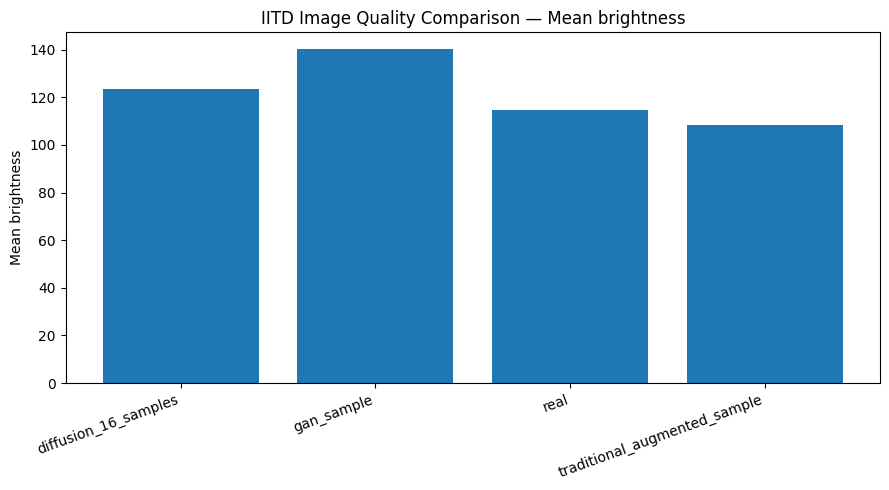

Saved: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook08_quality_diversity/IITD_comparison_brightness_mean.png


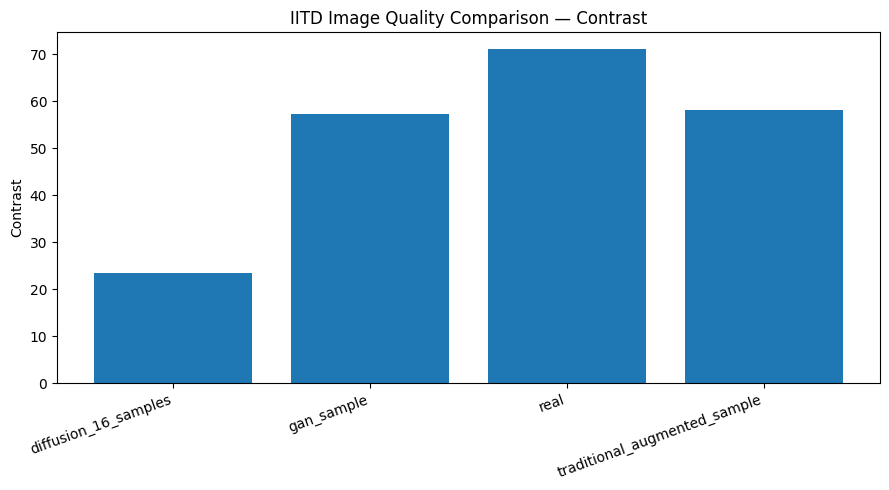

Saved: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook08_quality_diversity/IITD_comparison_contrast_std.png


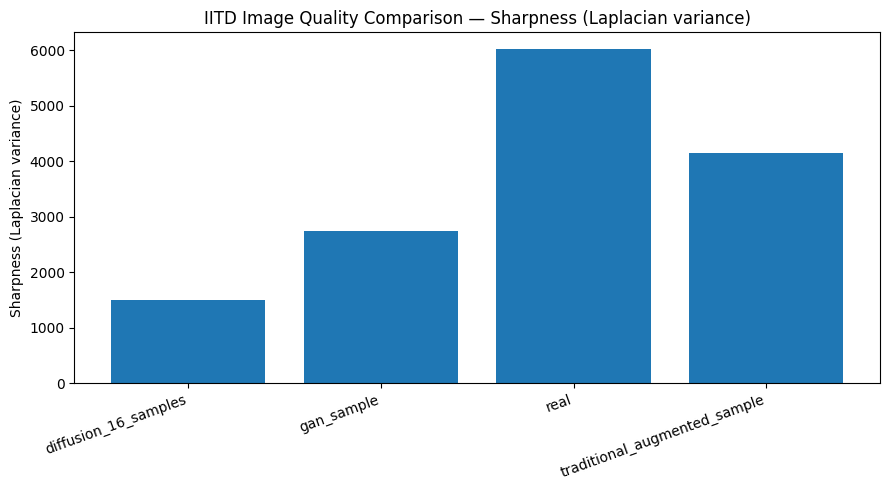

Saved: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook08_quality_diversity/IITD_comparison_sharpness_laplacian_variance.png


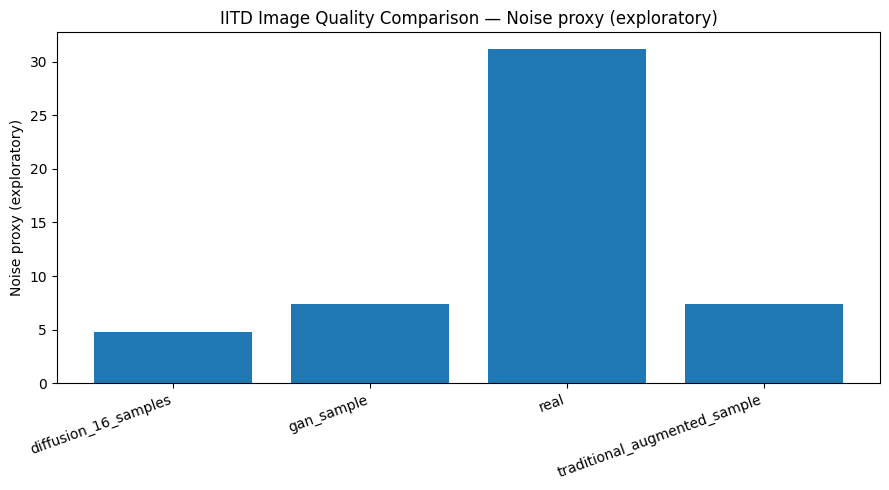

Saved: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook08_quality_diversity/IITD_comparison_noise_proxy.png

All comparison plots generated.


In [4]:

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

OUT_DIR = PROJECT / "results/IITD/notebook08_quality_diversity"
summary_path = OUT_DIR / "IITD_quality_diversity_all_metrics.csv"
df = pd.read_csv(summary_path)

metrics = [
    ("brightness_mean", "Mean brightness"),
    ("contrast_std", "Contrast"),
    ("sharpness_laplacian_variance", "Sharpness (Laplacian variance)"),
    ("noise_proxy", "Noise proxy (exploratory)")
]

for column, title in metrics:
    grouped = df.groupby("source")[column].agg(["mean", "std", "count"])
    grouped = grouped.dropna()

    plt.figure(figsize=(9, 5))
    plt.bar(grouped.index, grouped["mean"])
    plt.ylabel(title)
    plt.title(f"IITD Image Quality Comparison — {title}")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()

    filename = f"IITD_comparison_{column}.png"
    plt.savefig(OUT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", OUT_DIR / filename)

print("\nAll comparison plots generated.")


# Conclusion — Image Quality and Diversity Evaluation

This notebook evaluated the image-quality characteristics of the IIT Delhi ocular dataset and the available traditional, GAN-generated, and diffusion-generated samples. The analysis focused on brightness, contrast, Laplacian-variance sharpness, and an exploratory noise proxy.

## Evaluation Coverage

- Real images: 3,270 records using the quality metrics generated in Notebook 03.
- Traditional augmentation: a random sample of 100 images from the augmentation archive.
- GAN generation: a random sample of 100 generated images.
- Diffusion generation: 16 tiles extracted from the saved sample grid.

All newly evaluated images were converted to grayscale and resized to 64×64 before calculating the image statistics.

## Main Observations

The real-image reference had mean brightness of approximately 114.70, contrast of 71.10, and Laplacian-variance sharpness of 6,017.50.

The sampled traditional augmentations had mean brightness of 108.15, contrast of 58.04, and sharpness of 4,149.40.

The sampled GAN images had mean brightness of 140.24, contrast of 57.31, and sharpness of 2,738.36.

The 16 diffusion samples had mean brightness of 123.61, contrast of 23.50, and sharpness of 1,501.30. Their low contrast and sharpness are consistent with the blurry appearance observed in Notebook 07.

## Limitations

1. The traditional and GAN measurements use samples rather than the complete generated datasets.
2. The diffusion evaluation covers only 16 images and cannot establish the quality of a larger synthetic dataset.
3. The real-image metrics were inherited from Notebook 03, while the sampled synthetic and augmented images were recalculated using the fast evaluation function. The noise-proxy values should therefore not be treated as a perfectly standardized comparison.
4. Image statistics alone do not establish perceptual realism, identity preservation, privacy protection, or downstream recognition performance.
5. The GAN's proposed class labels are not verified biometric identities.

## Conclusion

The evaluation identified measurable differences between the real-image reference and the available augmentation outputs. In particular, the GAN and diffusion samples exhibited lower contrast and sharpness than the real-image reference. These findings agree with the visual limitations documented in the preceding notebooks.

The results are exploratory and should be interpreted as image-statistics comparisons, not proof that one augmentation method is superior for biometric recognition. Downstream recognition experiments are required to determine whether any augmentation method improves performance.